# Candidate Models

- **Logistic regression** is the linear baseline.
- **RBF SVM** gives a smooth nonlinear boundary in scaled feature space. It is wrapped in a sigmoid calibrator so it produces the class probabilities needed for ROC AUC and soft voting.
- **Random forest** is a bagged tree ensemble. It captures nonlinear effects and interactions without manual feature engineering.
- **XGBoost** is a gradient boosting model that can learn interactions such as the effect of `elo_diff` depending on `log_capacity` or `day_type`.
- **Soft voting** averages the class probabilities of the four individual models with equal weights.
- **Stacking** learns how much to trust each model from out-of-fold predictions. It is scored only on the test season, because its nested season folds cannot be formed inside a one-season outer training fold.

### How the data is used

- **Training seasons (2023, 2024)** are used for all comparison, tuning and selection, through season-grouped cross-validation.
- **Cross-validation folds** hold out one whole season each. Fold 1 trains on 2024 and validates on 2023, so it runs backwards in time. Fold 2 trains on 2023 and validates on 2024, so it runs forward in time. Both folds are reported separately.
- **Test season (2025):** an earlier notebook made an initial comparison of untuned models on this split. In this notebook it is not used for any tuning or selection decision. The selected model is fixed in section 7, before any model is fitted for the test evaluation in section 8, and test metrics are reported for every model for completeness only.

## 1. Setup

In [1]:
import json
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import xgboost
from IPython.display import display
from scipy.stats import loguniform, randint, uniform
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, StackingClassifier, VotingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, balanced_accuracy_score,
    classification_report, confusion_matrix, f1_score, precision_score,
    recall_score, roc_auc_score,
)
from sklearn.model_selection import GroupKFold, RandomizedSearchCV, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from xgboost import XGBClassifier

RANDOM_STATE = 42
N_JOBS = -1
JOBLIB_COMPRESS = 3

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
TRAIN_TEST_DIR = PROJECT_ROOT / "data" / "train_test_df"
FEATURES_DIR = PROJECT_ROOT / "data" / "processed" / "features"
RESULT_DIR = PROJECT_ROOT / "results" / "candidate_models"
RESULT_DIR.mkdir(parents=True, exist_ok=True)

## 2. Load and validate the split

In [2]:
X_train = pd.read_csv(TRAIN_TEST_DIR / "X_train.csv")
X_test = pd.read_csv(TRAIN_TEST_DIR / "X_test.csv")
y_train = pd.read_csv(TRAIN_TEST_DIR / "y_train.csv")["target"]
y_test = pd.read_csv(TRAIN_TEST_DIR / "y_test.csv")["target"]
train_full = pd.read_csv(FEATURES_DIR / "train_features.csv")
test_full = pd.read_csv(FEATURES_DIR / "test_features.csv")
with open(FEATURES_DIR / "feature_config.json", encoding="utf-8") as file:
    feature_config = json.load(file)

CLASS_LABELS = {int(key): value for key, value in feature_config["class_labels"].items()}
LABELS = sorted(CLASS_LABELS)
CLASS_NAMES = [CLASS_LABELS[label] for label in LABELS]

season_train = train_full["season"]
season_test = test_full["season"]
train_seasons = sorted(map(int, season_train.unique()))
test_seasons = sorted(map(int, season_test.unique()))

print(f"Training rows: {len(X_train):,} | Test rows: {len(X_test):,} | Features: {X_train.shape[1]}")
print(f"Training seasons: {train_seasons} | Test seasons: {test_seasons}")
class_counts = pd.DataFrame({"train_count": y_train.value_counts(), "test_count": y_test.value_counts()}).reindex(LABELS)
class_counts.index = CLASS_NAMES
class_counts.index.name = "turnout_class"
display(class_counts)

Training rows: 1,559 | Test rows: 806 | Features: 32
Training seasons: [2023, 2024] | Test seasons: [2025]


,train_count,test_count
turnout_class,,
low,520,238
medium,519,311
high,520,257


The split contains two training seasons and one later test season. The class mix differs somewhat between training and test, so accuracy alone could hide weak performance on one class. Every validation and test table therefore reports these metrics:

- **Accuracy**: the share of games predicted correctly.
- **Balanced accuracy**: the average share correct within each class, so every class counts equally.
- **Precision (macro)**: when the model predicts a class, how often it is right, averaged over the three classes.
- **Recall (macro)**: how many of the games of a class the model finds, averaged over the three classes.
- **F1 (macro)**: one number that combines precision and recall, averaged over the three classes.
- **ROC AUC**: how well the predicted probabilities separate the classes (0.5 is guessing, 1.0 is perfect).

**Macro F1** and **balanced accuracy** are the main metrics, because both weight the three classes equally.

## 3. Season-grouped cross-validation

Whole seasons are held out together, so no game from a validation season is used for training in that fold. The same `cv_splits` are used for the untuned comparison, every hyperparameter search and the model selection. The printout below states the training and validation seasons and the direction in time of each fold.

In [3]:
N_CV_FOLDS = min(5, season_train.nunique())
cv_splits = list(GroupKFold(n_splits=N_CV_FOLDS).split(X_train, y_train, groups=season_train))

FOLD_INFO = []
for fold, (train_idx, valid_idx) in enumerate(cv_splits, start=1):
    fold_train = sorted(map(int, season_train.iloc[train_idx].unique()))
    fold_valid = sorted(map(int, season_train.iloc[valid_idx].unique()))
    if max(fold_train) < min(fold_valid):
        direction = "forward in time"
    elif min(fold_train) > max(fold_valid):
        direction = "backward in time"
    else:
        direction = "mixed"
    FOLD_INFO.append({"fold": fold, "train_seasons": fold_train, "validation_seasons": fold_valid, "direction": direction})
    print(f"Fold {fold}: train on {fold_train}, validate on {fold_valid} ({direction})")

FOLD_NAMES = ["+".join(map(str, info["validation_seasons"])) for info in FOLD_INFO]

SCORING = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "precision_macro": "precision_macro",
    "recall_macro": "recall_macro",
    "f1_macro": "f1_macro",
    "roc_auc": "roc_auc_ovr",
}

Fold 1: train on [2024], validate on [2023] (backward in time)
Fold 2: train on [2023], validate on [2024] (forward in time)


## 4. Define the candidate models

Linear and kernel models are wrapped in a pipeline with median imputation and standard scaling. Tree models use imputation only, since they do not need scaled inputs. Imputers and scalers are fitted inside each cross-validation fold, so no statistics leak from the validation season.

In [4]:
def scaled_classifier(estimator):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", estimator),
    ])


models = {
    "dummy": DummyClassifier(strategy="prior", random_state=RANDOM_STATE),
    "logistic_regression": scaled_classifier(
        LogisticRegression(max_iter=2_000, class_weight="balanced", random_state=RANDOM_STATE)
    ),
    "svm_rbf": scaled_classifier(
        CalibratedClassifierCV(
            estimator=SVC(C=2.0, gamma="scale", class_weight="balanced"),
            method="sigmoid", cv=3,
        )
    ),
    "random_forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=400, max_features="sqrt", min_samples_leaf=2,
            class_weight="balanced", random_state=RANDOM_STATE, n_jobs=N_JOBS,
        )),
    ]),
    "xgboost": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", XGBClassifier(
            n_estimators=300, max_depth=3, learning_rate=0.05,
            subsample=0.85, colsample_bytree=0.85,
            objective="multi:softprob", num_class=len(LABELS),
            eval_metric="mlogloss", tree_method="hist",
            random_state=RANDOM_STATE, n_jobs=N_JOBS,
        )),
    ]),
}
BASE_NAMES = ["logistic_regression", "svm_rbf", "random_forest", "xgboost"]
models["soft_voting"] = VotingClassifier(
    estimators=[(name, models[name]) for name in BASE_NAMES], voting="soft", n_jobs=N_JOBS
)
models["stacking_cv"] = StackingClassifier(
    estimators=[(name, models[name]) for name in BASE_NAMES],
    final_estimator=LogisticRegression(max_iter=2_000, class_weight="balanced", random_state=RANDOM_STATE),
    stack_method="predict_proba", cv=cv_splits, n_jobs=N_JOBS,
)
print("Models:", ", ".join(models))

Models: dummy, logistic_regression, svm_rbf, random_forest, xgboost, soft_voting, stacking_cv


## 5. Untuned candidate comparison

Every candidate is scored with the same season-grouped folds. The dummy model sets the floor, the individual models test different decision rules, and soft voting tests whether averaging probabilities helps. In addition to the mean and standard deviation across folds, the macro F1 of each fold is reported under the season it validates on (`f1_macro_val_<season>`), so the backward and forward folds can be compared directly.

Stacking is not ranked here, for the reason given in the introduction.

In [5]:
def cv_summary(model_dict, version):
    rows = []
    for name, model in model_dict.items():
        scores = cross_validate(
            clone(model), X_train, y_train, groups=season_train,
            cv=cv_splits, scoring=SCORING, n_jobs=1,
            return_train_score=False, error_score="raise",
        )
        row = {"model": name, "version": version}
        for metric in SCORING:
            row[f"cv_{metric}"] = scores[f"test_{metric}"].mean()
            row[f"cv_{metric}_std"] = scores[f"test_{metric}"].std()
        for fold_name, value in zip(FOLD_NAMES, scores["test_f1_macro"]):
            row[f"f1_macro_val_{fold_name}"] = value
        row["cv_fit_seconds"] = scores["fit_time"].sum()
        rows.append(row)
    return pd.DataFrame(rows).set_index("model").sort_values("cv_f1_macro", ascending=False)


def show_scores(frame):
    numeric = frame.select_dtypes("number").columns
    display(frame.style.format({column: "{:.3f}" for column in numeric}))


untuned_candidates = {name: models[name] for name in ["dummy", *BASE_NAMES, "soft_voting"]}
untuned_cv = cv_summary(untuned_candidates, "untuned")
show_scores(untuned_cv)

c:\Users\emirl\Sports-Analytics-1B-assessing-football-stadium-attendance-and-experience\bttenv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\emirl\Sports-Analytics-1B-assessing-football-stadium-attendance-and-experience\bttenv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


,version,cv_accuracy,cv_accuracy_std,cv_balanced_accuracy,cv_balanced_accuracy_std,cv_precision_macro,cv_precision_macro_std,cv_recall_macro,cv_recall_macro_std,cv_f1_macro,cv_f1_macro_std,cv_roc_auc,cv_roc_auc_std,f1_macro_val_2023,f1_macro_val_2024,cv_fit_seconds
model,,,,,,,,,,,,,,,,
random_forest,untuned,0.744,0.019,0.743,0.018,0.763,0.002,0.743,0.018,0.747,0.014,0.896,0.005,0.733,0.760,0.887
soft_voting,untuned,0.713,0.015,0.714,0.013,0.726,0.014,0.714,0.013,0.715,0.012,0.882,0.004,0.704,0.727,6.385
xgboost,untuned,0.705,0.020,0.705,0.020,0.728,0.001,0.705,0.020,0.707,0.014,0.881,0.011,0.693,0.721,1.013
svm_rbf,untuned,0.666,0.036,0.668,0.033,0.667,0.037,0.668,0.033,0.663,0.034,0.835,0.016,0.629,0.697,0.112
logistic_regression,untuned,0.647,0.032,0.651,0.033,0.681,0.003,0.651,0.033,0.642,0.032,0.849,0.006,0.674,0.610,0.032
dummy,untuned,0.318,0.001,0.333,0.000,0.106,0.000,0.333,0.000,0.161,0.000,0.500,0.000,0.160,0.161,0.003


### Findings: untuned models

- The dummy model, which only guesses from the class shares, scores about 0.32 accuracy and 0.16 macro F1. Every real model is clearly better than that.
- **Random forest** is the best untuned model (macro F1 0.747, accuracy 0.744), followed by soft voting (0.715), XGBoost (0.707), the SVM (0.663) and logistic regression (0.642).
- The two tree models beat the simple models by a wide margin. This suggests that the link between the features and turnout is not a simple straight line.
- Logistic regression and the SVM also change more from one fold to the other (spread of about 0.03, against about 0.014 for the tree models), so their results are less steady.

## 6. Hyperparameter tuning with grouped CV

Each of the four individual models is tuned separately with a small randomized search that optimizes grouped-CV macro F1 on the training seasons only. The search spaces adjust parameters that control complexity or regularization, and the number of iterations is kept small because only two validation seasons are available and a long search would fit those two seasons rather than generalize.

Every tuned model is carried forward to the ensembles and the selection step whether or not tuning improved it. This keeps the protocol fixed in advance. How much tuning changed each score is reported in section 7.

In [ ]:
SEARCHES = {
    "logistic_regression": (
        models["logistic_regression"],
        {"model__C": loguniform(1e-3, 1e2)}, 10,
    ),
    "svm_rbf": (
        models["svm_rbf"],
        {
            "model__estimator__C": loguniform(1e-1, 1e2),
            "model__estimator__gamma": loguniform(1e-4, 1e-1),
        }, 10,
    ),
    "random_forest": (
        models["random_forest"],
        {
            "model__max_depth": randint(4, 13),
            "model__min_samples_leaf": randint(2, 31),
            "model__max_features": ["sqrt", 0.3, 0.5],
        }, 12,
    ),
    "xgboost": (
        models["xgboost"],
        {
            "model__n_estimators": randint(100, 500),
            "model__max_depth": randint(2, 6),
            "model__min_child_weight": randint(1, 10),
            "model__subsample": uniform(0.6, 0.4),
            "model__colsample_bytree": uniform(0.6, 0.4),
            "model__reg_lambda": uniform(1, 9),
        }, 12,
    ),
}


def to_native(value):
    return value.item() if isinstance(value, np.generic) else value


tuned_models, tuned_params, tuning_rows, top_config_frames = {}, {}, [], []
for name, (estimator, distributions, n_iter) in SEARCHES.items():
    search = RandomizedSearchCV(
        estimator=estimator, param_distributions=distributions, n_iter=n_iter,
        scoring="f1_macro", cv=cv_splits, refit=True,
        random_state=RANDOM_STATE, n_jobs=1, error_score="raise",
    )
    started = time.perf_counter()
    search.fit(X_train, y_train)
    tuned_models[name] = search.best_estimator_
    tuned_params[name] = {key: to_native(value) for key, value in search.best_params_.items()}
    tuning_rows.append({
        "model": name, "n_iter": n_iter,
        "best_cv_f1_macro": search.best_score_,
        "search_seconds": time.perf_counter() - started,
        "best_params": json.dumps(tuned_params[name]),
    })

    results = pd.DataFrame(search.cv_results_).sort_values("rank_test_score").head(5)
    fold_score_columns = [c for c in results.columns if c.startswith("split") and c.endswith("_test_score")]
    top = results[["rank_test_score", "mean_test_score", "std_test_score", *fold_score_columns]].copy()
    top.insert(0, "model", name)
    top["params"] = [json.dumps({k: to_native(v) for k, v in p.items()}) for p in results["params"]]
    top_config_frames.append(top)
    print(f"{name}: best grouped-CV macro F1 = {search.best_score_:.3f}")

tuning_summary = pd.DataFrame(tuning_rows).set_index("model")
top_configs = pd.concat(top_config_frames, ignore_index=True)
display(tuning_summary)

logistic_regression: best grouped-CV macro F1 = 0.677
svm_rbf: best grouped-CV macro F1 = 0.677


The five best configurations of each search are kept in `top_configs`.

In [ ]:
display(top_configs.drop(columns="params").style.format({
    c: "{:.3f}" for c in top_configs.select_dtypes("number").columns if c != "rank_test_score"
}))

,model,rank_test_score,mean_test_score,std_test_score,split0_test_score,split1_test_score
0,logistic_regression,1,0.677,0.003,0.680,0.674
1,logistic_regression,1,0.677,0.003,0.680,0.674
2,logistic_regression,3,0.668,0.014,0.654,0.682
3,logistic_regression,4,0.649,0.026,0.674,0.623
4,logistic_regression,5,0.642,0.032,0.674,0.610
5,svm_rbf,1,0.677,0.031,0.646,0.707
6,svm_rbf,2,0.674,0.018,0.656,0.692
7,svm_rbf,3,0.657,0.038,0.619,0.695
8,svm_rbf,4,0.652,0.009,0.643,0.660
9,svm_rbf,5,0.641,0.012,0.652,0.629


## 7. Tuned comparison and model selection

The ensembles are rebuilt from the tuned individual models. Soft voting is then scored with the same grouped folds. The model is selected here, using grouped-CV macro F1 only, among the four tuned individual models and tuned soft voting. No test-season prediction has been made at this point in the notebook.

In [ ]:
tuned_voting = VotingClassifier(
    estimators=[(name, tuned_models[name]) for name in BASE_NAMES],
    voting="soft", n_jobs=N_JOBS,
)
tuned_stacking = StackingClassifier(
    estimators=[(name, tuned_models[name]) for name in BASE_NAMES],
    final_estimator=LogisticRegression(max_iter=2_000, class_weight="balanced", random_state=RANDOM_STATE),
    stack_method="predict_proba", cv=cv_splits, n_jobs=N_JOBS,
)

tuned_candidates = {**tuned_models, "soft_voting": tuned_voting}
tuned_cv = cv_summary(tuned_candidates, "tuned")
cv_all = pd.concat([untuned_cv, tuned_cv]).sort_values("cv_f1_macro", ascending=False)
show_scores(cv_all)

,version,cv_accuracy,cv_accuracy_std,cv_balanced_accuracy,cv_balanced_accuracy_std,cv_precision_macro,cv_precision_macro_std,cv_recall_macro,cv_recall_macro_std,cv_f1_macro,cv_f1_macro_std,cv_roc_auc,cv_roc_auc_std,f1_macro_val_2023,f1_macro_val_2024,cv_fit_seconds
model,,,,,,,,,,,,,,,,
random_forest,untuned,0.744,0.019,0.743,0.018,0.763,0.002,0.743,0.018,0.747,0.014,0.896,0.005,0.733,0.760,0.937
random_forest,tuned,0.744,0.005,0.743,0.003,0.754,0.007,0.743,0.003,0.744,0.001,0.889,0.002,0.745,0.742,0.926
xgboost,tuned,0.738,0.014,0.737,0.013,0.755,0.001,0.737,0.013,0.740,0.009,0.890,0.009,0.731,0.749,0.439
soft_voting,tuned,0.720,0.012,0.720,0.010,0.726,0.004,0.720,0.010,0.720,0.008,0.883,0.006,0.713,0.728,5.396
soft_voting,untuned,0.713,0.015,0.714,0.013,0.726,0.014,0.714,0.013,0.715,0.012,0.882,0.004,0.704,0.727,5.984
xgboost,untuned,0.705,0.020,0.705,0.020,0.728,0.001,0.705,0.020,0.707,0.014,0.881,0.011,0.693,0.721,0.912
logistic_regression,tuned,0.679,0.001,0.678,0.001,0.677,0.005,0.678,0.001,0.677,0.003,0.835,0.003,0.680,0.674,0.039
svm_rbf,tuned,0.683,0.028,0.685,0.024,0.686,0.027,0.685,0.024,0.677,0.031,0.836,0.019,0.646,0.707,0.124
svm_rbf,untuned,0.666,0.036,0.668,0.033,0.667,0.037,0.668,0.033,0.663,0.034,0.835,0.016,0.629,0.697,0.159


### Effect of tuning

The table compares the untuned and tuned grouped-CV macro F1 of each model. A change smaller than the fold-to-fold differences in the table above should not be read as a real improvement or decline.

In [ ]:
compared = [*BASE_NAMES, "soft_voting"]
tuning_effects = pd.DataFrame({
    "untuned_cv_f1_macro": untuned_cv.loc[compared, "cv_f1_macro"],
    "tuned_cv_f1_macro": tuned_cv.loc[compared, "cv_f1_macro"],
})
tuning_effects["change"] = tuning_effects["tuned_cv_f1_macro"] - tuning_effects["untuned_cv_f1_macro"]
display(tuning_effects.style.format("{:.3f}"))

,untuned_cv_f1_macro,tuned_cv_f1_macro,change
model,,,
logistic_regression,0.642,0.677,0.035
svm_rbf,0.663,0.677,0.014
random_forest,0.747,0.744,-0.003
xgboost,0.707,0.740,0.033
soft_voting,0.715,0.720,0.005


### Findings: tuning

- After tuning, random forest (0.744) and XGBoost (0.740) are still far ahead of logistic regression and the SVM (both 0.677).
- Tuning helped logistic regression (+0.035) and XGBoost (+0.033) the most, and the SVM a little (+0.014). Random forest did not change (-0.003) and soft voting moved only slightly (+0.005).
- Changes of about 0.005 or less are too small to count as a real gain, because the two folds differ by about that much on their own.

### Selection rule

The pre-specified rule is to select the tuned model with the highest grouped-CV macro F1 among the four individual models and tuned soft voting. The cell below applies the rule and compares the margin over the runner-up with the spread between the two folds of the winner. If the margin is smaller than that spread, the selection is reported as a statistical tie that the rule resolved, not as evidence that the winner is better.

In [ ]:
SELECTION_CANDIDATES = [*BASE_NAMES, "soft_voting"]
fold_columns = [f"f1_macro_val_{fold_name}" for fold_name in FOLD_NAMES]

ranking = tuned_cv.loc[SELECTION_CANDIDATES].sort_values("cv_f1_macro", ascending=False)
best_model_name = ranking.index[0]
runner_up_name = ranking.index[1]
selection_margin = ranking.iloc[0]["cv_f1_macro"] - ranking.iloc[1]["cv_f1_macro"]
fold_spread = ranking.loc[best_model_name, fold_columns].max() - ranking.loc[best_model_name, fold_columns].min()
selection_is_tie = bool(selection_margin < fold_spread)

show_scores(ranking[["cv_accuracy", "cv_balanced_accuracy", "cv_precision_macro", "cv_recall_macro", "cv_f1_macro", *fold_columns, "cv_roc_auc"]])
print(f"Selected by grouped-CV macro F1: {best_model_name}")
print(f"Runner-up: {runner_up_name} | margin: {selection_margin:.3f} | fold-to-fold spread of the winner: {fold_spread:.3f}")

,cv_accuracy,cv_balanced_accuracy,cv_precision_macro,cv_recall_macro,cv_f1_macro,f1_macro_val_2023,f1_macro_val_2024,cv_roc_auc
model,,,,,,,,
random_forest,0.744,0.743,0.754,0.743,0.744,0.745,0.742,0.889
xgboost,0.738,0.737,0.755,0.737,0.740,0.731,0.749,0.890
soft_voting,0.720,0.720,0.726,0.720,0.720,0.713,0.728,0.883
logistic_regression,0.679,0.678,0.677,0.678,0.677,0.680,0.674,0.835
svm_rbf,0.683,0.685,0.686,0.685,0.677,0.646,0.707,0.836


Selected by grouped-CV macro F1: random_forest
Runner-up: xgboost | margin: 0.004 | fold-to-fold spread of the winner: 0.003


### Findings: model selection

- **Random forest is selected.** It has the highest validation macro F1 (0.744), just ahead of XGBoost (0.740).
- The lead is only 0.004, so these two models are in practice about equal. Random forest wins under the rule we set in advance, and it is also the steadier one: its score is almost the same on both validation seasons (0.745 and 0.742), while XGBoost moves more (0.731 and 0.749).
- Soft voting (0.720) did not beat its best member, so averaging the four models did not help here.

### Out-of-fold per-class behavior

To see where each candidate makes its errors, every selection candidate is refitted on each training fold and its predictions on the held-out season are pooled. These out-of-fold predictions come only from training seasons. The medium class sits between low and high and is expected to be the hardest, so the per-class recall in the table is the main thing to read.

,f1_low,f1_medium,f1_high,recall_low,recall_medium,recall_high
model,,,,,,
random_forest,0.793,0.644,0.800,0.804,0.665,0.763
xgboost,0.784,0.651,0.789,0.762,0.703,0.748
soft_voting,0.783,0.601,0.778,0.777,0.613,0.769
logistic_regression,0.772,0.539,0.722,0.777,0.534,0.725
svm_rbf,0.775,0.521,0.732,0.790,0.478,0.779


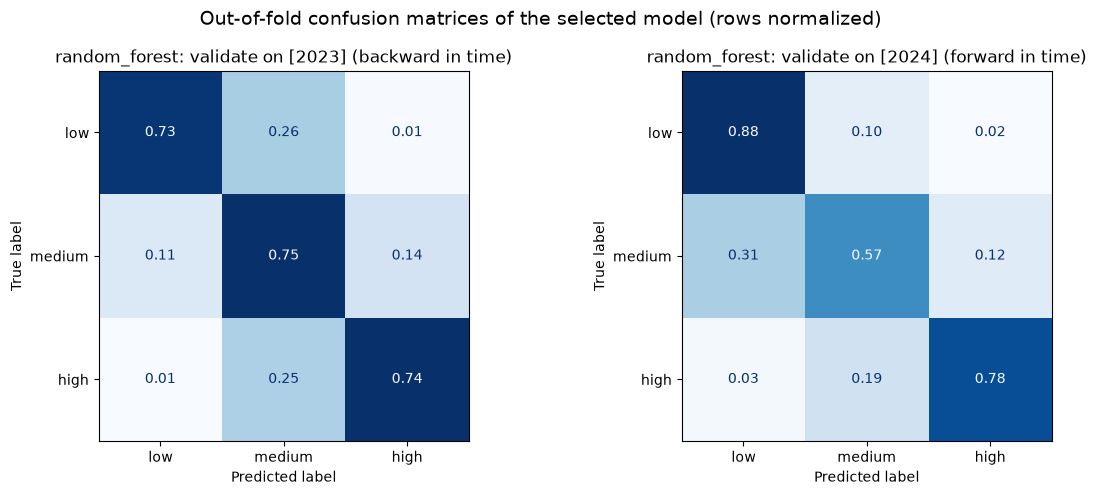

In [ ]:
def oof_by_fold(model):
    folds = []
    for train_idx, valid_idx in cv_splits:
        fitted = clone(model).fit(X_train.iloc[train_idx], y_train.iloc[train_idx])
        folds.append((y_train.iloc[valid_idx].to_numpy(), fitted.predict(X_train.iloc[valid_idx])))
    return folds


oof = {name: oof_by_fold(tuned_candidates[name]) for name in SELECTION_CANDIDATES}

per_class_rows = {}
for name, folds in oof.items():
    y_true_all = np.concatenate([fold[0] for fold in folds])
    y_pred_all = np.concatenate([fold[1] for fold in folds])
    f1_values = f1_score(y_true_all, y_pred_all, labels=LABELS, average=None, zero_division=0)
    recall_values = recall_score(y_true_all, y_pred_all, labels=LABELS, average=None, zero_division=0)
    per_class_rows[name] = {
        **{f"f1_{label}": value for label, value in zip(CLASS_NAMES, f1_values)},
        **{f"recall_{label}": value for label, value in zip(CLASS_NAMES, recall_values)},
    }
cv_per_class = pd.DataFrame(per_class_rows).T.loc[ranking.index]
cv_per_class.index.name = "model"
display(cv_per_class.style.format("{:.3f}"))

fig, axes = plt.subplots(1, len(oof[best_model_name]), figsize=(6 * len(oof[best_model_name]), 5))
for ax, (y_true_fold, y_pred_fold), info in zip(np.atleast_1d(axes), oof[best_model_name], FOLD_INFO):
    ConfusionMatrixDisplay.from_predictions(
        y_true_fold, y_pred_fold, labels=LABELS, display_labels=CLASS_NAMES,
        normalize="true", values_format=".2f", cmap="Blues", colorbar=False, ax=ax,
    )
    ax.set_title(f"{best_model_name}: validate on {info['validation_seasons']} ({info['direction']})")
fig.suptitle("Out-of-fold confusion matrices of the selected model (rows normalized)", fontsize=14)
fig.tight_layout()
plt.show()

### Findings: errors by class

- For every model, the **medium** class is the hardest. Medium games sit between low and high, so they are the easiest to mix up with either side.
- For the selected random forest, F1 is about 0.79 for low, 0.64 for medium and 0.80 for high, and it finds about two thirds of the medium games (recall 0.665).
- XGBoost finds slightly more medium games (recall 0.703) but is a bit weaker on low and high.
- Logistic regression and the SVM find fewer than 54% of medium games, which is the main reason they score lower.

## 8. Test evaluation

The selected model was fixed in section 7. Here every model family, untuned and tuned, is fitted on all training seasons and scored on the 2025 season. These numbers describe how each model performed and are not used to change any decision. The table below lists the tuned models in the order of their grouped-CV rank, not in the order of their test score, with the dummy model first and stacking last because it has no CV rank.

In [ ]:
def metric_row(y_true, prediction, probability):
    return {
        "accuracy": accuracy_score(y_true, prediction),
        "balanced_accuracy": balanced_accuracy_score(y_true, prediction),
        "precision_macro": precision_score(y_true, prediction, average="macro", zero_division=0),
        "recall_macro": recall_score(y_true, prediction, average="macro", zero_division=0),
        "f1_macro": f1_score(y_true, prediction, average="macro", zero_division=0),
        "roc_auc_ovr": roc_auc_score(y_true, probability, multi_class="ovr", labels=LABELS),
    }


model_versions = {
    "dummy": {"not_tuned": models["dummy"]},
    **{name: {"not_tuned": models[name], "tuned": tuned_models[name]} for name in BASE_NAMES},
    "soft_voting": {"not_tuned": models["soft_voting"], "tuned": tuned_voting},
    "stacking": {"not_tuned": models["stacking_cv"], "tuned": tuned_stacking},
}

fitted_models, test_predictions, test_probabilities, test_rows = {}, {}, {}, []
for family, versions in model_versions.items():
    for version, estimator in versions.items():
        started = time.perf_counter()
        fitted = clone(estimator).fit(X_train, y_train)
        fit_seconds = time.perf_counter() - started
        key = (family, version)
        fitted_models[key] = fitted
        test_predictions[key] = fitted.predict(X_test)
        test_probabilities[key] = fitted.predict_proba(X_test)
        test_rows.append({
            "model": family, "version": version,
            **metric_row(y_test, test_predictions[key], test_probabilities[key]),
            "fit_seconds": fit_seconds,
        })

test_results = pd.DataFrame(test_rows).set_index(["model", "version"])
display_order = [("dummy", "not_tuned"), *[(name, "tuned") for name in ranking.index], ("stacking", "tuned")]
test_table = test_results.loc[display_order].copy()
test_table["selected"] = [family == best_model_name and version == "tuned" for family, version in test_table.index]
display(test_table.style.format({c: "{:.3f}" for c in test_table.select_dtypes("float").columns}))

,,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,roc_auc_ovr,fit_seconds,selected
model,version,,,,,,,,
dummy,not_tuned,0.295,0.333,0.098,0.333,0.152,0.500,0.001,False
random_forest,tuned,0.768,0.778,0.770,0.778,0.771,0.911,0.470,True
xgboost,tuned,0.773,0.783,0.775,0.783,0.776,0.919,0.242,False
soft_voting,tuned,0.757,0.771,0.757,0.771,0.759,0.916,0.696,False
logistic_regression,tuned,0.726,0.743,0.728,0.743,0.727,0.888,0.021,False
svm_rbf,tuned,0.708,0.733,0.712,0.733,0.702,0.879,0.136,False
stacking,tuned,0.770,0.782,0.772,0.782,0.773,0.919,1.590,False


In [ ]:
selected_key = (best_model_name, "tuned")
selected_model = fitted_models[selected_key]
print(f"Selected model: {best_model_name} (chosen from grouped CV in section 7)")
print(f"Grouped-CV macro F1: {tuned_cv.loc[best_model_name, 'cv_f1_macro']:.3f}")
print(f"Test macro F1: {test_results.loc[selected_key, 'f1_macro']:.3f} | test accuracy: {test_results.loc[selected_key, 'accuracy']:.3f}")
print()
print(classification_report(y_test, test_predictions[selected_key], labels=LABELS, target_names=CLASS_NAMES, zero_division=0))

Selected model: random_forest (chosen from grouped CV in section 7)
Grouped-CV macro F1: 0.744
Test macro F1: 0.771 | test accuracy: 0.768

              precision    recall  f1-score   support

         low       0.75      0.90      0.82       238
      medium       0.75      0.67      0.71       311
        high       0.81      0.77      0.79       257

    accuracy                           0.77       806
   macro avg       0.77      0.78      0.77       806
weighted avg       0.77      0.77      0.77       806



### Findings: test season (2025)

- The selected **random forest** scores 0.771 macro F1, 0.768 accuracy, 0.778 balanced accuracy, 0.770 precision, 0.778 recall and 0.911 ROC AUC. This is a little higher than its validation score (0.744), which is likely because the final model learns from both training seasons instead of one.
- XGBoost (0.776), stacking (0.773) and random forest (0.771) are within 0.005 of each other, so there is no real difference between them. Soft voting is a bit lower (0.759), logistic regression is at 0.727 and the SVM at 0.702. The dummy model gets 0.152.
- The test ranking agrees with the validation ranking: tree models first, linear and SVM models last. The best test model was XGBoost, but the selection was already fixed, so this changes nothing.

## 9. Error analysis on the test season

The confusion matrices show which classes each model mixes up. Errors between low and medium, or between medium and high, are understandable because those classes are adjacent in turnout. Low-to-high errors are more serious because they are a larger miss in expected stadium experience.

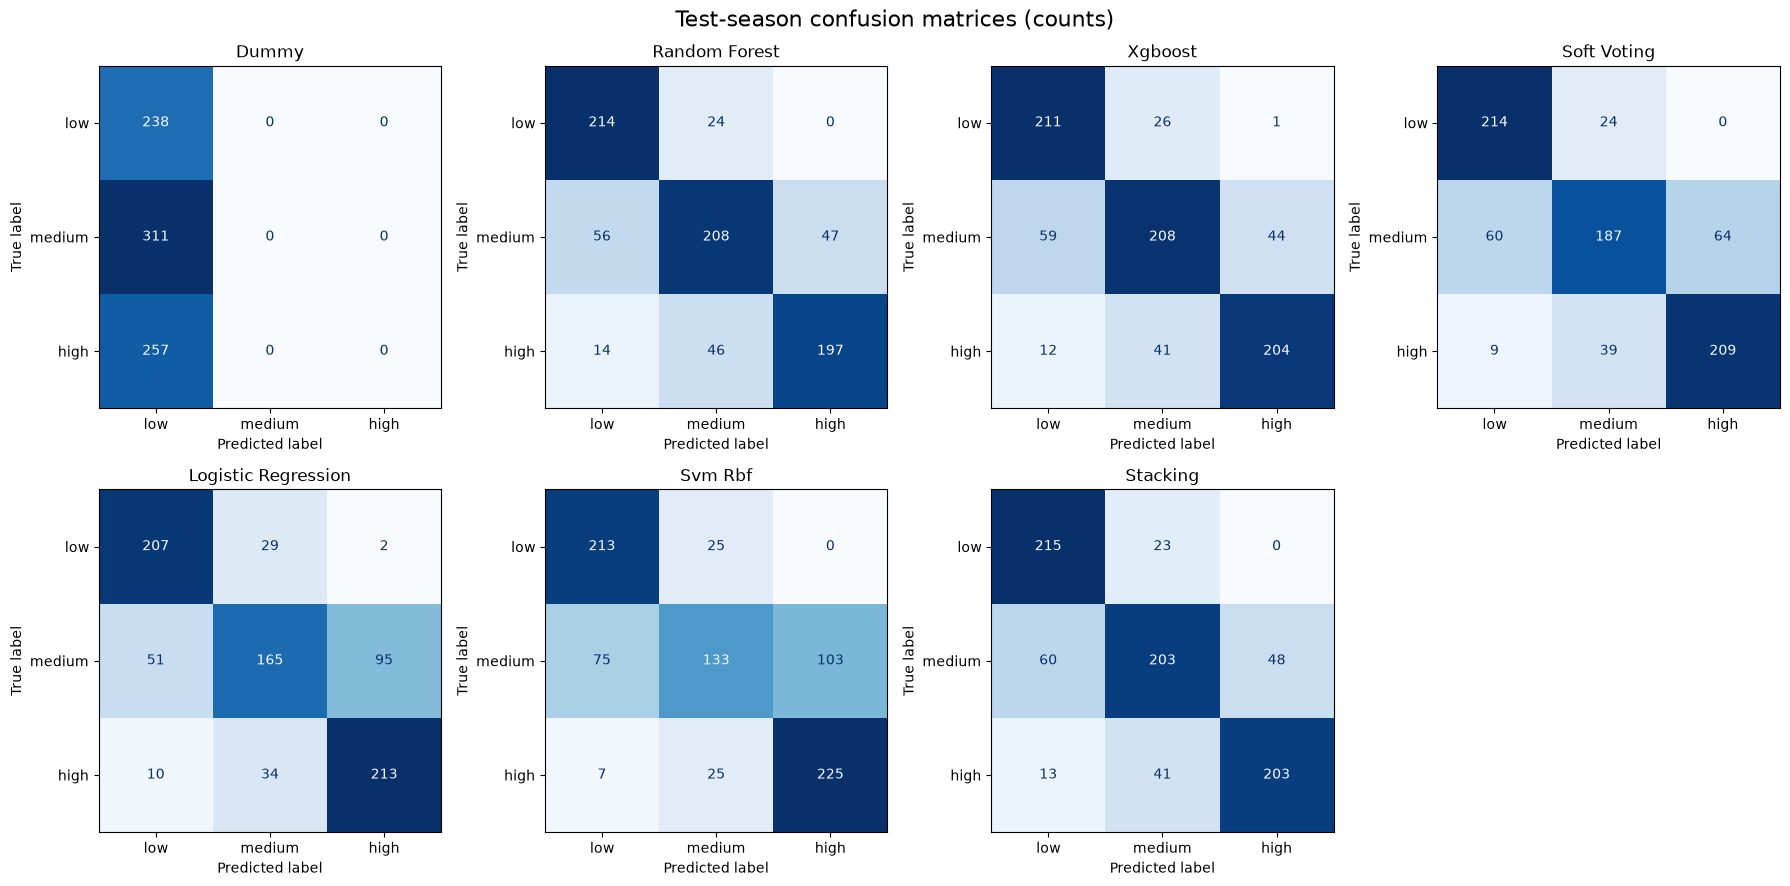

,precision,recall,f1-score,support
low,0.754,0.899,0.820,238
medium,0.748,0.669,0.706,311
high,0.807,0.767,0.786,257
accuracy,0.768,0.768,0.768,1
macro avg,0.770,0.778,0.771,806
weighted avg,0.769,0.768,0.765,806


In [ ]:
grid_keys = [("dummy", "not_tuned"), *[(name, "tuned") for name in ranking.index], ("stacking", "tuned")]
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for ax, key in zip(axes.flat, grid_keys):
    ConfusionMatrixDisplay.from_predictions(
        y_test, test_predictions[key], labels=LABELS,
        display_labels=CLASS_NAMES, cmap="Blues", values_format="d",
        colorbar=False, ax=ax,
    )
    ax.set_title(key[0].replace("_", " ").title())
for ax in list(axes.flat)[len(grid_keys):]:
    ax.axis("off")
fig.suptitle("Test-season confusion matrices (counts)", fontsize=16)
fig.tight_layout()
plt.show()

selected_report = pd.DataFrame(classification_report(
    y_test, test_predictions[selected_key], labels=LABELS,
    target_names=CLASS_NAMES, output_dict=True, zero_division=0,
)).T
display(selected_report.style.format({"precision": "{:.3f}", "recall": "{:.3f}", "f1-score": "{:.3f}", "support": "{:.0f}"}))

In [ ]:
overall = test_results.loc[selected_key]
overall_table = pd.DataFrame({
    "random forest (tuned)": overall[[
        "accuracy", "balanced_accuracy", "precision_macro",
        "recall_macro", "f1_macro", "roc_auc_ovr",
    ]]
})
overall_table.index = [
    "accuracy", "balanced accuracy", "macro precision",
    "macro recall", "macro f1", "macro roc auc (one-vs-rest)",
]
display(overall_table.style.format("{:.3f}"))

,random forest (tuned)
accuracy,0.768
balanced accuracy,0.778
macro precision,0.770
macro recall,0.778
macro f1,0.771
macro roc auc (one-vs-rest),0.911


### Findings: test errors

- For the random forest, the model finds 90% of low games, 77% of high games and 67% of medium games.
- Most mistakes are between neighbouring classes. It never predicted high for a low game, and only 14 of 257 high games were predicted as low.
- Medium games are the main problem: 56 were predicted low and 47 were predicted high.
- Logistic regression and the SVM mix up medium and high much more (95 and 103 medium games predicted as high), which again shows why they trail the tree models.

## 10. Save results

Only the most useful files are saved:

- `cv_comparison.csv`: validation scores of every model, untuned and tuned.
- `model_comparison.csv`: test scores of every model.
- `best_params.json`: the best settings found for each model.
- `run_metadata.json`: the selection rule, the chosen model, the seasons, the feature list and the library versions.
- `selected_model.joblib`: the selected model, fitted on the training seasons.

The model file depends on the library versions recorded in `run_metadata.json`.

In [ ]:
# comparison tables
cv_all.reset_index().round(6).to_csv(RESULT_DIR / "cv_comparison.csv", index=False)
test_results.round(6).reset_index().to_csv(RESULT_DIR / "model_comparison.csv", index=False)

# best settings and run details
with open(RESULT_DIR / "best_params.json", "w", encoding="utf-8") as file:
    json.dump(tuned_params, file, indent=2)

run_metadata = {
    "random_state": RANDOM_STATE,
    "selection_rule": "highest grouped-CV macro F1 among tuned individual models and tuned soft voting, fixed before test evaluation",
    "selection_candidates": SELECTION_CANDIDATES,
    "selected_model": best_model_name,
    "runner_up": runner_up_name,
    "selection_margin_cv_f1_macro": float(selection_margin),
    "selected_model_fold_spread_f1_macro": float(fold_spread),
    "selection_is_statistical_tie": selection_is_tie,
    "cv_folds": FOLD_INFO,
    "train_seasons": train_seasons,
    "test_seasons": test_seasons,
    "feature_columns": list(X_train.columns),
    "class_labels": {str(key): value for key, value in CLASS_LABELS.items()},
    "library_versions": {"scikit-learn": sklearn.__version__, "xgboost": xgboost.__version__, "pandas": pd.__version__, "joblib": joblib.__version__},
    "run_time_utc": pd.Timestamp.now(tz="UTC").isoformat(),
}
with open(RESULT_DIR / "run_metadata.json", "w", encoding="utf-8") as file:
    json.dump(run_metadata, file, indent=2)

# the selected model
joblib.dump(selected_model, RESULT_DIR / "selected_model.joblib", compress=JOBLIB_COMPRESS)

print(f"Results saved")

Saved results


## 11. Findings and conclusion

**Selected model: random forest.** It was chosen using validation scores only (macro F1 0.744), before anything was predicted on the test season.

**What we found**

- All models beat the dummy baseline by a large margin, so the features contain real information about turnout.
- Tree models (random forest and XGBoost) clearly beat logistic regression and the SVM, both on validation and on the test season.
- On the 2025 test season, the random forest reaches about 77% accuracy and 0.771 macro F1, with precision and recall both near 0.77. The model is correct about three times out of four.
- Low and high turnout are predicted well. Medium turnout is the weak spot: only about two thirds of medium games are found, and the mistakes are almost always toward the neighbouring class.

**What to keep in mind**

- Random forest and XGBoost are very close, so the choice between them is not strong. Either one would be reasonable.
- With only two training seasons and one test season, small score differences should not be over-read.

### Why the random forest is only slightly better than the baseline

On the 2025 test season, the tuned random forest (macro F1 0.771) is only about 0.01 ahead of the plain logistic regression baseline (macro F1 0.761). For this season the two models perform about the same.

The likely reasons are:

- **The features carry most of the signal.** The engineered features already describe turnout well, so even a simple model can use them. A more flexible model has little left to add.
- **The baseline was not weak on the test season.** It trains on both 2023 and 2024 and uses default settings. The tuned logistic regression in this notebook scored lower (0.727) because the search chose very strict regularization on validation folds that train on only one season, and that setting did not carry over to the test season.
- **Validation is a harder test, and it separates the models more.** When a model must predict a season it has never seen after learning from only one season, the tree models are clearly ahead of logistic regression (macro F1 0.744 against 0.642 for the untuned version). This suggests random forest is the more reliable choice for new seasons, even though 2025 alone does not show a big gap.
- **Only one test season is available.** A gap of 0.01 on one season cannot be separated from chance, so it should not be read as a clear win.
- **The hardest class is the same for every model.** Medium turnout sits between low and high, and all models find only about two thirds of those games. Better features for the medium class would probably help more than a different model.

**Conclusion:** the random forest was selected from validation scores before the test season was used, and it is slightly ahead of the baseline on the test season. The improvement is small, so the main takeaway is that the features are strong, not that the model choice matters a lot.